# Themes

The editor ships with three themes. A theme file picks one of them as its base
and changes some colours, sizes or fonts. This notebook lists the built-in
themes, writes a small theme file, applies it to an app and draws the colours it
changes. Python only checks the shape of the file; the browser checks each
key.

In [1]:
# Standard library
import io
import json
from pathlib import Path

In [2]:
# Third-party libraries
import matplotlib.pyplot as plt
from IPython import display as ipython_display

In [3]:
# Local libraries
import element_51
from element_51.theme import DEFAULT_THEME, THEME_NAMES, resolve_theme

In [4]:
# Files go in a scratch folder, never in the project
OUT = Path("__data__")
OUT.mkdir(exist_ok=True)
THEME_FILE = OUT / "my_theme.json"

## The built-in themes

In [5]:
for name in THEME_NAMES:
    marker = " (default)" if name == DEFAULT_THEME else ""
    print(name + marker)
assert DEFAULT_THEME in THEME_NAMES

antimony
antimony-light
purple-synthwave (default)


In [6]:
app = element_51.App([])
print("a new app uses", app.theme)
app.theme = "antimony-light"
print("after the change", app.theme)
assert app.theme == "antimony-light"

a new app uses purple-synthwave
after the change antimony-light


## A theme file

`base` names the theme to start from. Everything else lists only what changes.
Here: a darker blue canvas, a warmer header and a rounder card.

In [7]:
CHANGES = {
    "base": "antimony",
    "colours": {
        "canvas": "#101820",
        "dot": "#1c2a36",
        "header": "#2b4a63",
        "card": "#17212b",
    },
    "metrics": {"card_radius": 12},
}
THEME_FILE.write_text(json.dumps(CHANGES, indent=4), "utf-8")
theme = resolve_theme(THEME_FILE)
print(theme.base, sorted(theme.colours), theme.metrics)
assert theme.base == "antimony"
assert theme.colours == CHANGES["colours"]

antimony ['canvas', 'card', 'dot', 'header'] {'card_radius': 12.0}


In [8]:
app.theme = THEME_FILE
print("the app now draws on", app.theme, "with the file's changes")
assert app.theme == "antimony"

the app now draws on antimony with the file's changes


The colours the file changes, side by side:

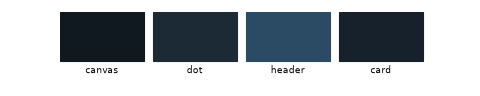

In [9]:
figure, axis = plt.subplots(figsize=(6, 1.2))
for position, (name, colour) in enumerate(theme.colours.items()):
    axis.add_patch(plt.Rectangle((position, 0), 0.9, 1, color=colour))
    axis.text(position + 0.45, -0.25, name, ha="center", fontsize=8)
axis.set_xlim(0, len(theme.colours))
axis.set_ylim(-0.5, 1)
axis.axis("off")
buffer = io.BytesIO()
figure.savefig(buffer, format="png", dpi=80)
plt.close(figure)
ipython_display.display(ipython_display.Image(data=buffer.getvalue()))
assert buffer.getbuffer().nbytes > 0

## Names and files that are not themes

In [10]:
choices = ["antimony-dark", str(OUT / "missing.json")]
messages = []
for choice in choices:
    try:
        resolve_theme(choice)
    except ValueError as error:
        messages.append(str(error))
        print(error)
assert len(messages) == len(choices)

unknown theme 'antimony-dark': it is not a built-in theme (antimony, antimony-light, purple-synthwave) and not a file
unknown theme '__data__/missing.json': it is not a built-in theme (antimony, antimony-light, purple-synthwave) and not a file
